In [ ]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


# Blood CD4 CTL vs CD8 expression

In [2]:
bl_5p  <- readRDS('../251029_VN_PREDICT3/data/SCP/Blood_CD3NK_5p.rds')

In [3]:
bl_3p  <- readRDS('../251029_VN_PREDICT3/data/SCP/Blood_CD3NK_3p.rds')

In [6]:
bl_3p$cd4_ctl  %>% table

.
 FALSE   TRUE 
323613    926 

In [7]:
md_blood_3p  <- write.csv(bl_3p@meta.data, "tables/261018_blood_3p_metadata.csv")

In [23]:
bl_5p$cd4_ctl  %>% table

.
 FALSE   TRUE 
591958   1616 

In [10]:
bl_3p$seurat_clusters  %>% table

.
     2      4      1      3      8     10      7      5     11      6      9 
128539  29873  52177  22261  17349  15740  20593  11697   7444   7327   6744 
    13     12 
  2727   2068 

In [8]:
bl_5p$seurat_clusters_and_ctl  <- if_else(bl_5p$cd4_ctl,"CTL",bl_5p$seurat_clusters)
bl_3p$seurat_clusters_and_ctl  <- if_else(bl_3p$cd4_ctl,"CTL",bl_3p$seurat_clusters)


In [9]:
bl_5p$seurat_clusters_and_ctl  %>% table

.
     1     10     11     12     13      2      3      4      5      6      7 
106441  25271  15721   4840   3882 196865  57801  62393  17024  12014  27184 
     8      9    CTL 
 39620  22902   1616 

## 5p

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



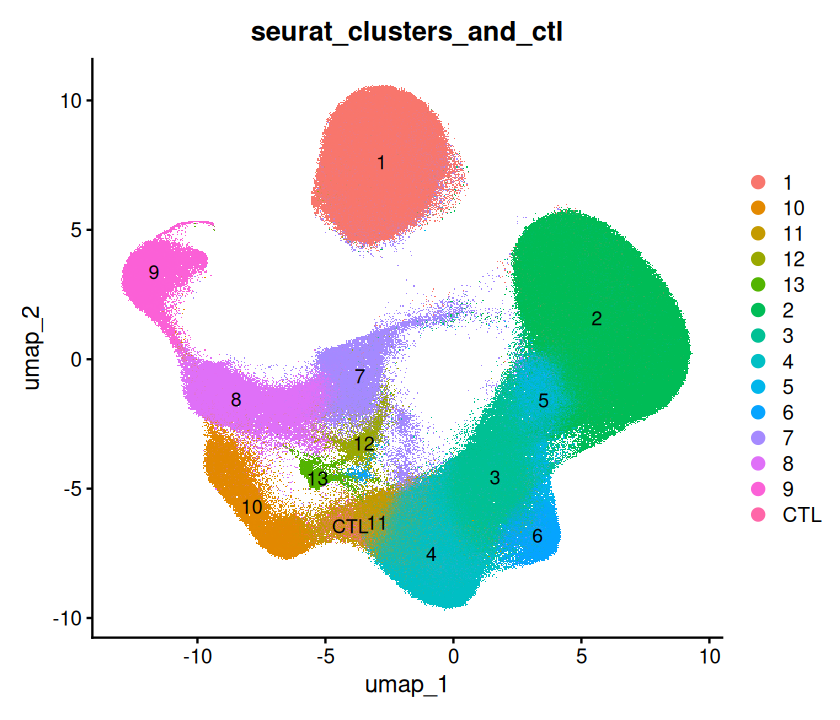

In [149]:
DimPlot(bl_5p, group.by = "seurat_clusters_and_ctl", label = T)

In [11]:
pallete_blood_5p  <- c(
"1" =  "#89b8da",
"2" =  "#F1CE63",
"3" =  '#D39200',
"4" =  '#AAA300',
"5" =  'indianred2',
"6" =  '#FF61C9',
"7" =  '#00B6EB',
"8" =  '#00BFC2',
"9" =  '#00C08C',
"10" =  "#9D7660" ,
"11" =  '#6DB100',
"12" =  '#D4A6C8',
"13" =  '#B07AA1',
    "CTL" = "red"
)

In [12]:
bl_5p$seurat_clusters_and_ctl <- factor(
  bl_5p$seurat_clusters_and_ctl,
  levels = c(as.character(1:13), "CTL")
)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



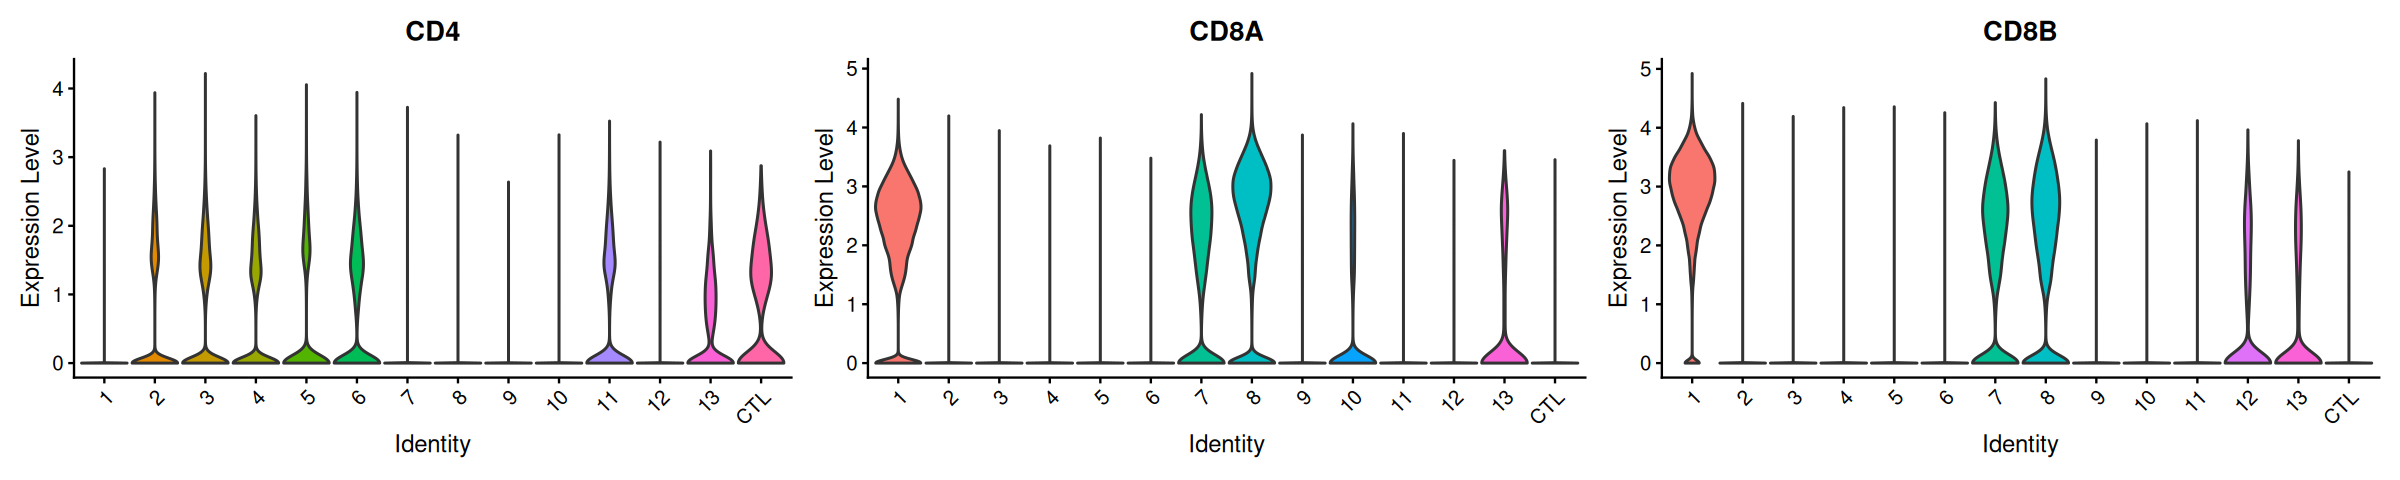

In [13]:
options(repr.plot.width = 20, repr.plot.height = 4)
VlnPlot(bl_5p, features = c("CD4","CD8A","CD8B"), pt.size = 0, 
       group.by = "seurat_clusters_and_ctl",assay = "RNA")


In [152]:

ggsave("figures/vlnplot_blood_cd4_cd8_5p.svg", width = 32, height = 9, units = "cm")
ggsave("figures/vlnplot_blood_cd4_cd8_5p.png", width = 32, height = 9, units = "cm")

In [16]:
DefaultAssay(bl_5p)  <- "RNA"

In [17]:
genes <- c("CD8A", "CD8B", "CD4")

# Extract expression and annotations
df <- FetchData(
  bl_5p,
  vars = c(genes, "seurat_clusters_and_ctl"),
  layer = "counts"
)

# Calculate percentage of positive cells per annotation
df_summary <- df %>%
  pivot_longer(
    cols = all_of(genes),
    names_to = "gene",
    values_to = "expression"
  ) %>%
  group_by(seurat_clusters_and_ctl, gene) %>%
  summarise(
    percent_positive = mean(expression > 0) * 100,
    .groups = "drop"
  )

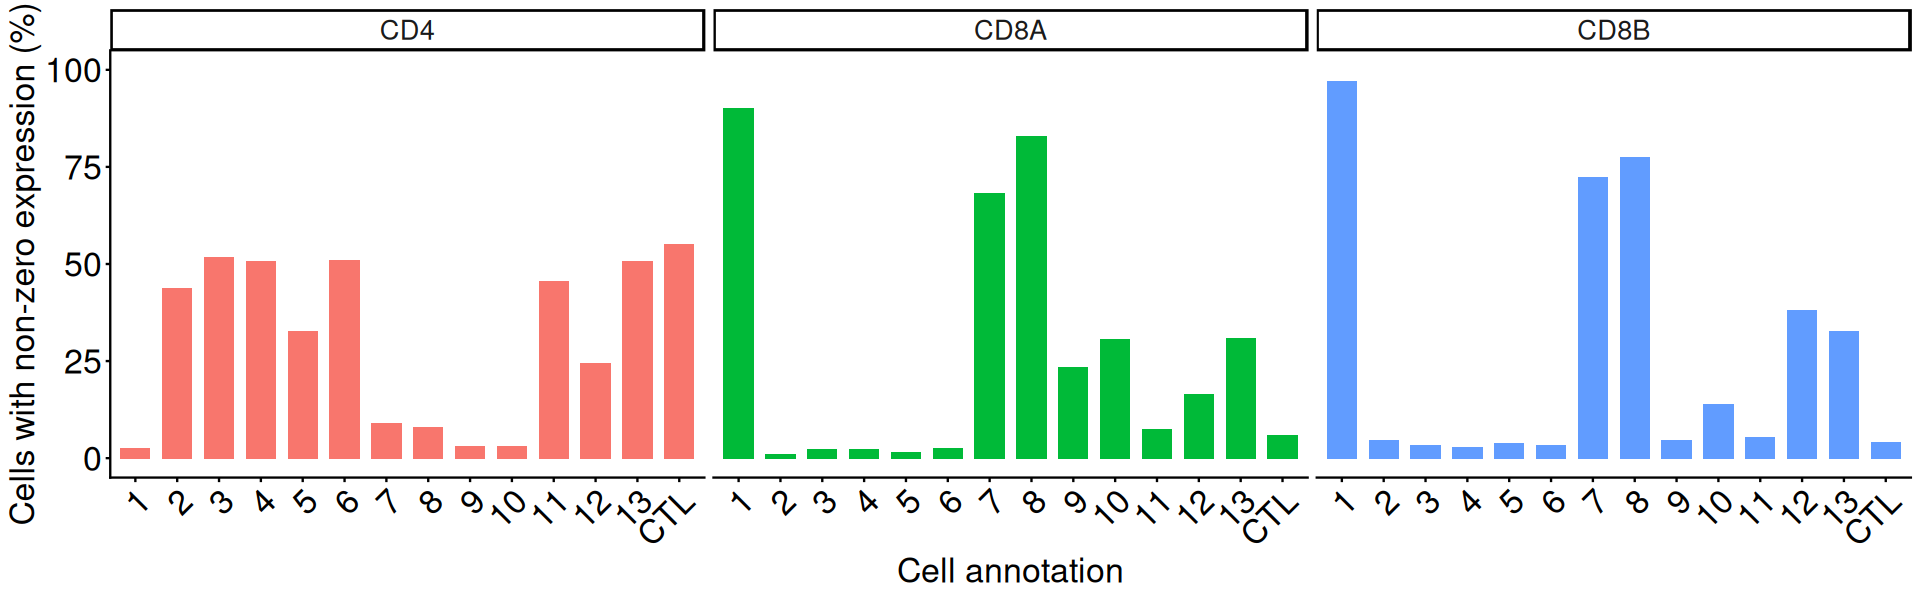

In [27]:
ggplot(df_summary,
       aes(x = seurat_clusters_and_ctl,
           y = percent_positive,
           fill = gene)) +
  geom_col(width = 0.7) +
  facet_wrap(~ gene, nrow = 1) +
  scale_y_continuous(limits = c(0, 100)) +
  labs(
    x = "Cell annotation",
    y = "Cells with non-zero expression (%)"
  ) +
  theme_classic() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "none"
  ) +
ggtheme()

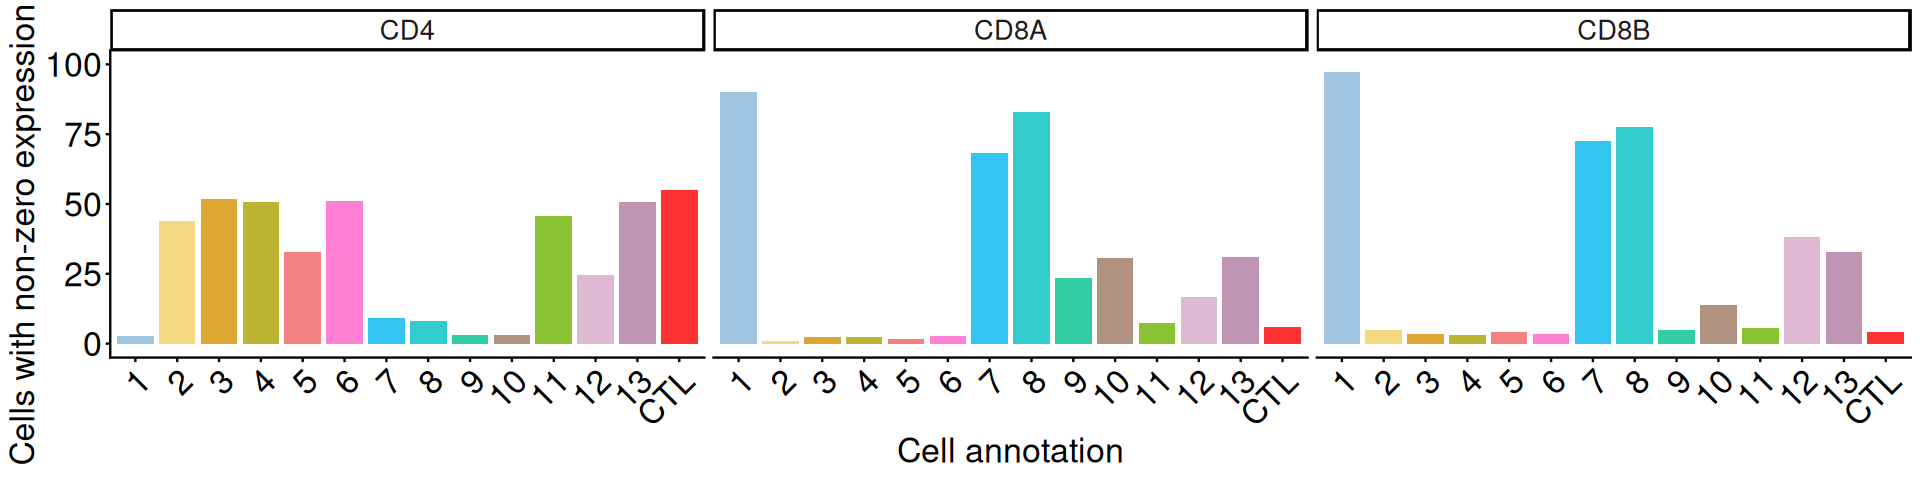

In [28]:
options(repr.plot.width = 16, repr.plot.height = 4)
ggplot(df_summary,
       aes(x = seurat_clusters_and_ctl,
           y = percent_positive,
           fill = seurat_clusters_and_ctl)) +
  geom_col(width = 0.85, alpha = 0.8) +
  facet_wrap(~ gene, nrow = 1) +
  scale_fill_manual(values = pallete_blood_5p) +
  scale_y_continuous(limits = c(0, 100)) +
  labs(
    x = "Cell annotation",
    y = "Cells with non-zero expression (%)"
  ) +
  theme_classic() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "none"
  ) +
ggtheme()

In [30]:

ggsave("figures/barplot_blood_cd4_cd8_5p.svg", width = 34, height = 9, units = "cm")
ggsave("figures/barplot_blood_cd4_cd8_5p.png", width = 34, height = 9, units = "cm")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



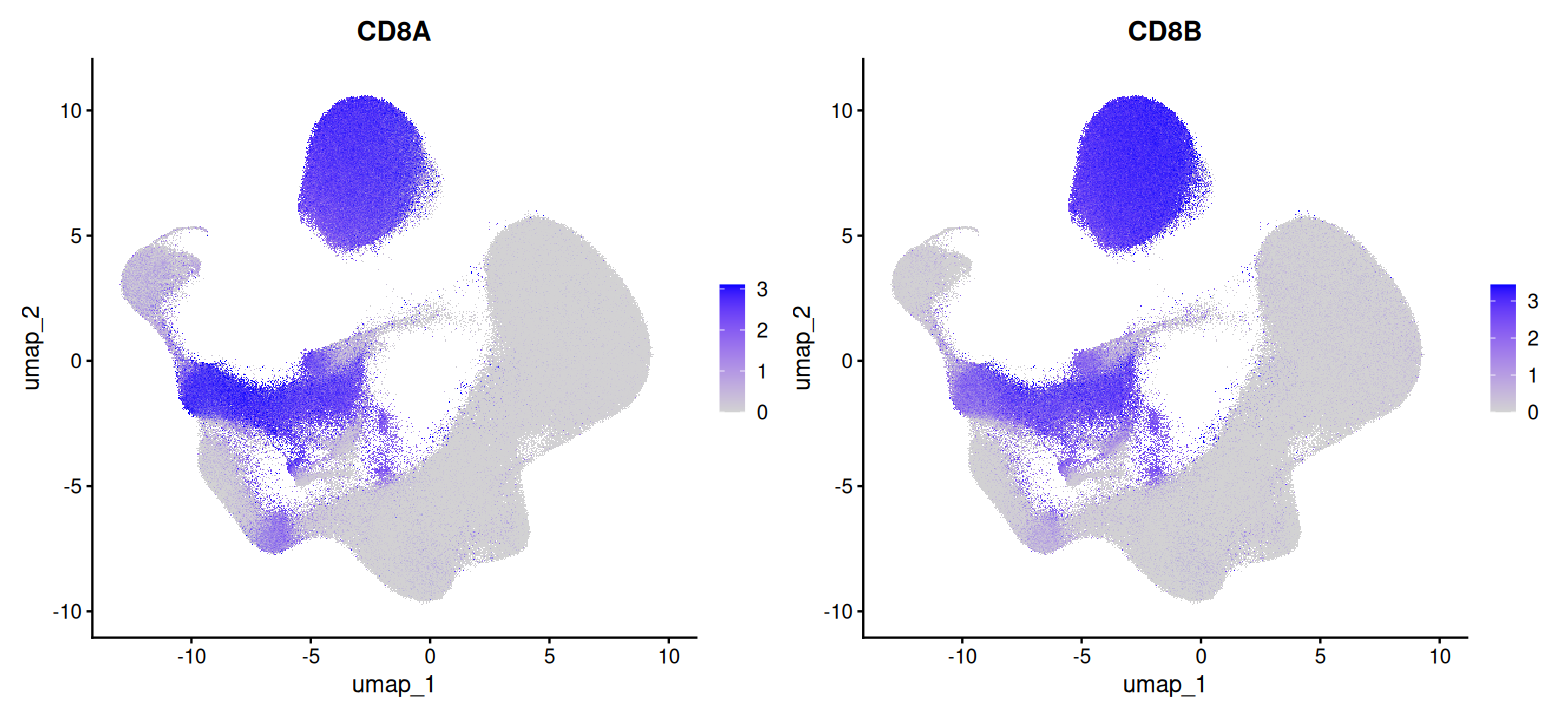

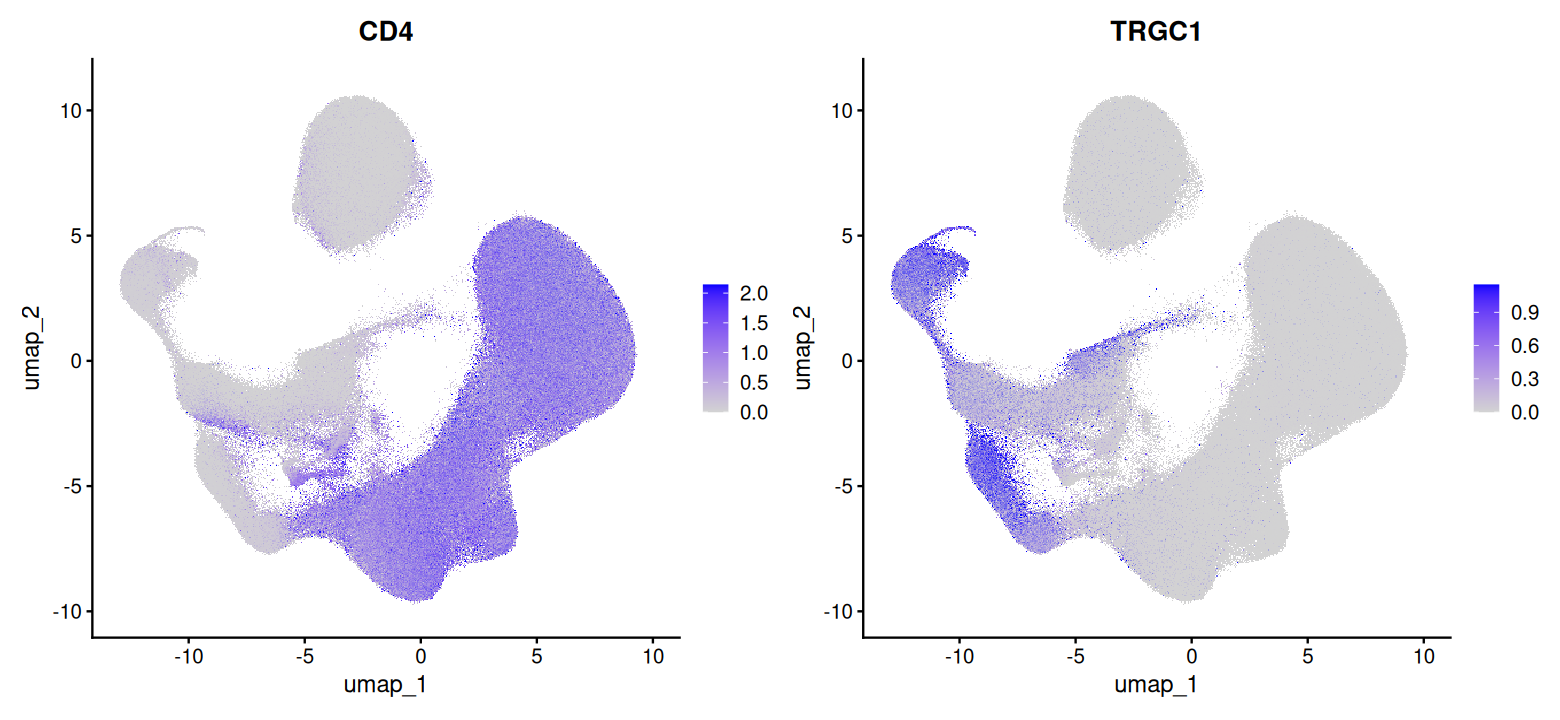

In [130]:
options(repr.plot.width = 13, repr.plot.height = 6)

FeaturePlot(bl_5p, features = c("CD8A","CD8B"), ncol = 2, min.cutoff = 0, max.cutoff = "q95")

FeaturePlot(bl_5p, features = c("CD4","TRGC1"), ncol = 2, min.cutoff = 0, max.cutoff = "q95")

## 3p

In [153]:
bl_3p$seurat_clusters_and_ctl  <- factor(bl_3p$seurat_clusters_and_ctl, levels = c(1:13,"CTL"))

In [145]:
bl_3p$seurat_clusters  %>% table

.
     2      4      1      3      8     10      7      5     11      6      9 
128539  29873  52177  22261  17349  15740  20593  11697   7444   7327   6744 
    13     12 
  2727   2068 

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



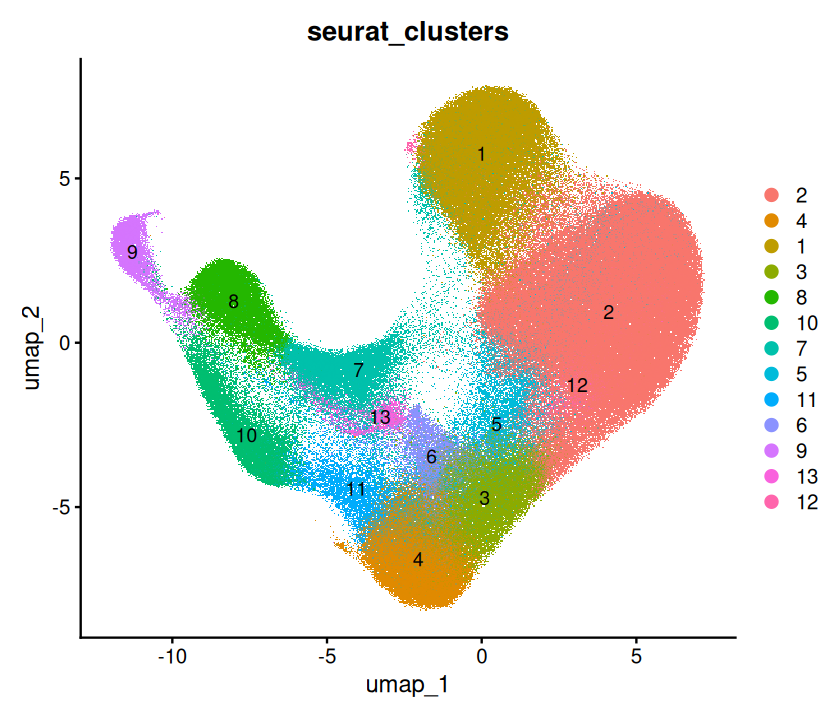

In [154]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(bl_3p, group.by = "seurat_clusters", label = T)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



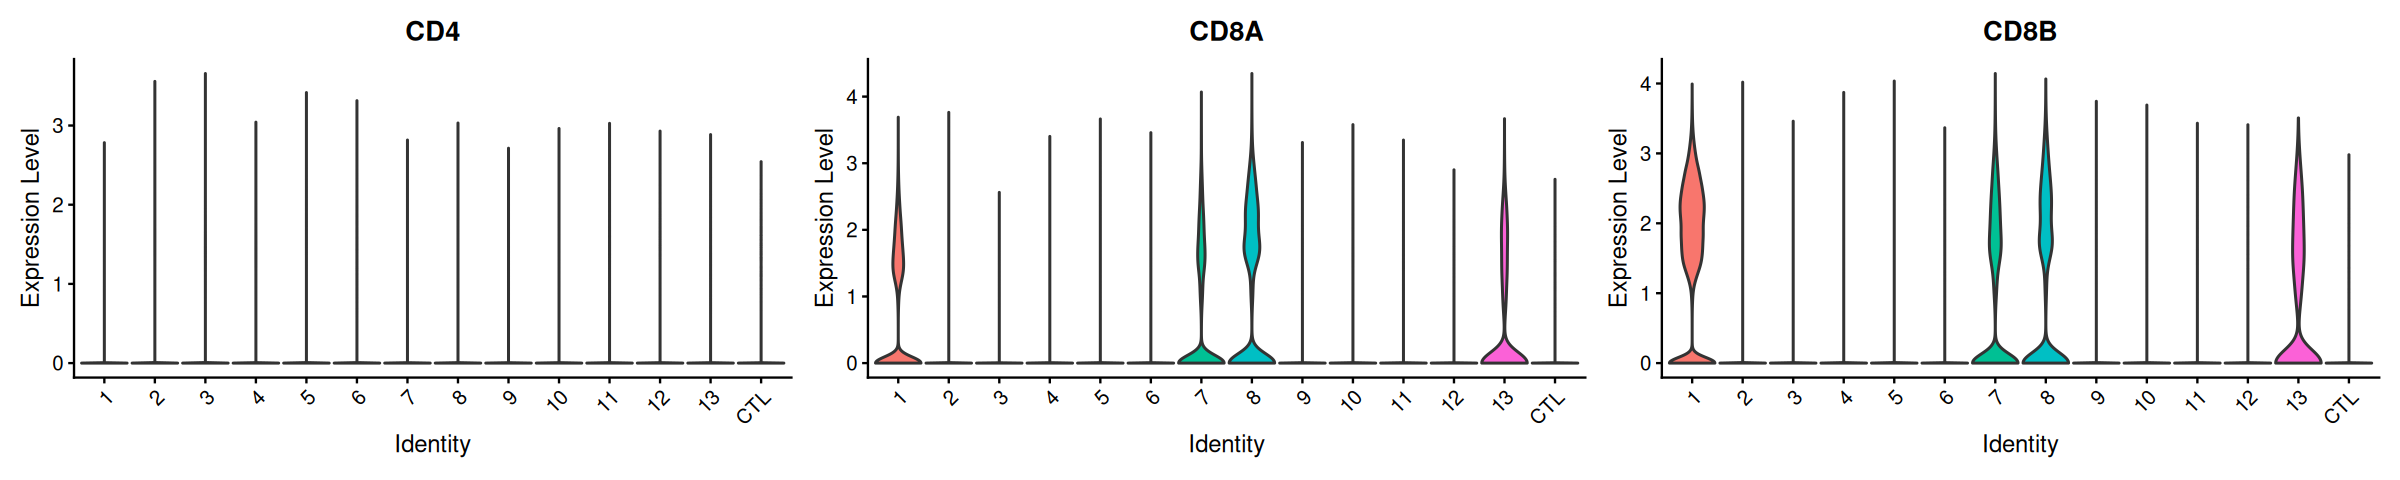

In [155]:
options(repr.plot.width = 20, repr.plot.height = 4)
VlnPlot(bl_3p, features = c("CD4","CD8A","CD8B"), pt.size = 0, 
       group.by = "seurat_clusters_and_ctl", assay = "RNA")

In [156]:

ggsave("figures/vlnplot_blood_cd4_cd8_3p.svg", width = 32, height = 9, units = "cm")
ggsave("figures/vlnplot_blood_cd4_cd8_3p.png", width = 32, height = 9, units = "cm")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



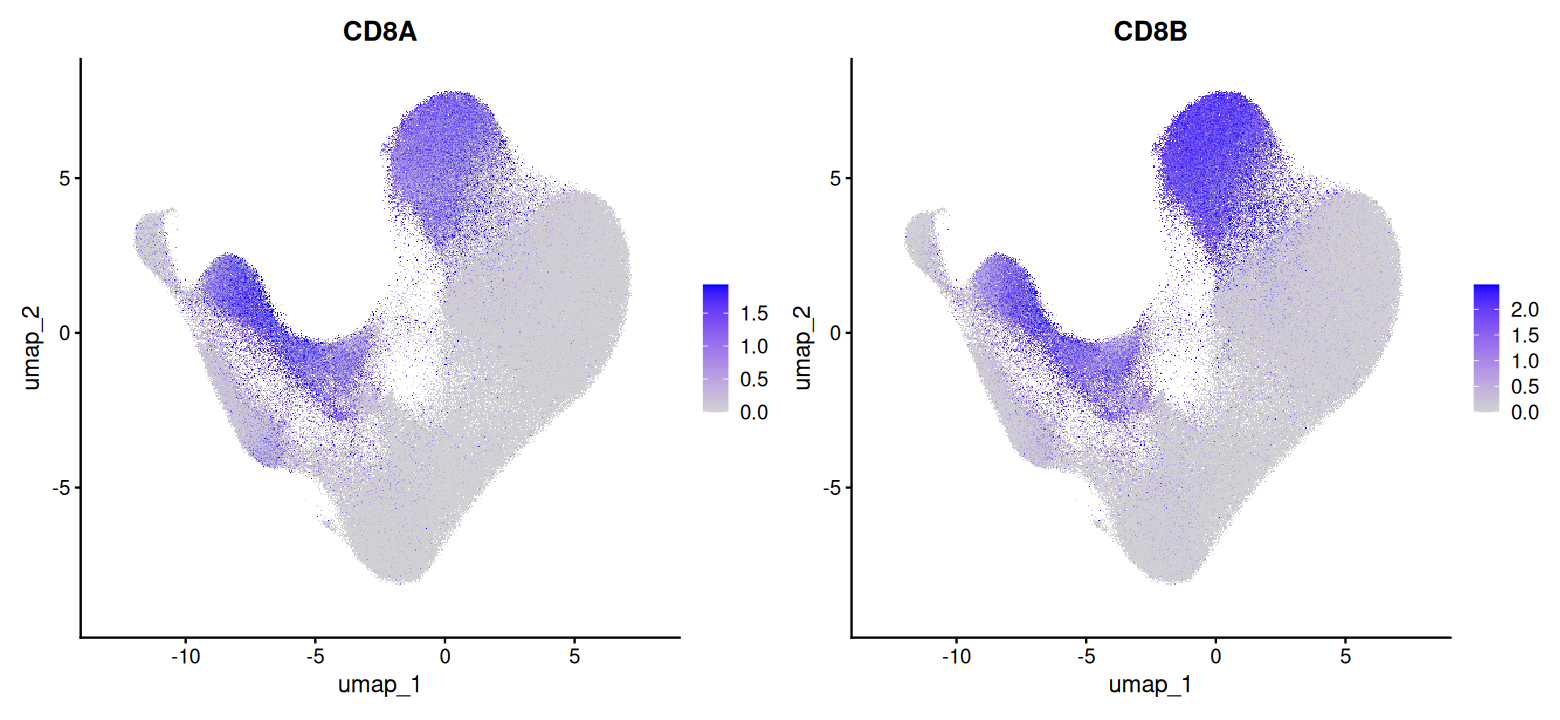

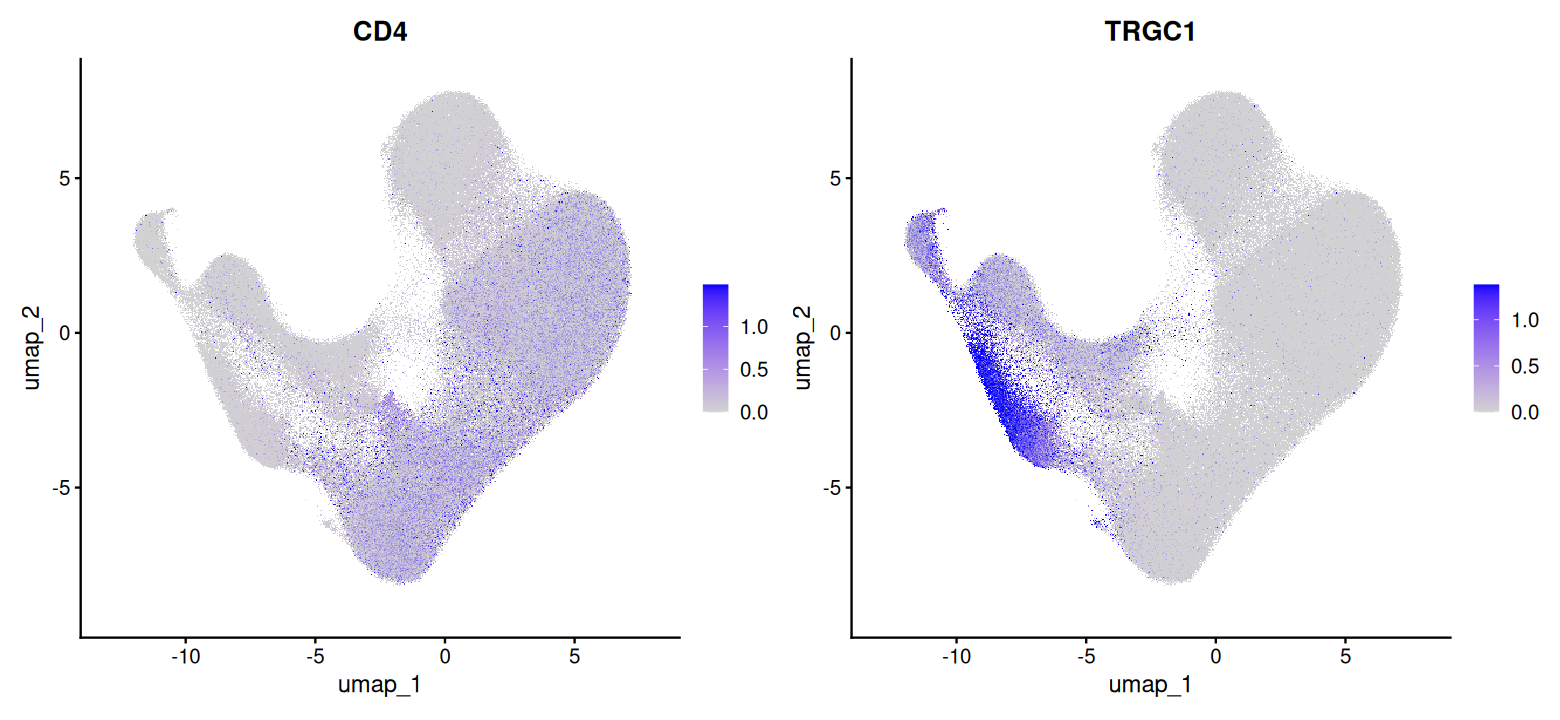

In [137]:
options(repr.plot.width = 13, repr.plot.height = 6)

FeaturePlot(bl_3p, features = c("CD8A","CD8B"), ncol = 2, min.cutoff = 0, max.cutoff = "q95")

FeaturePlot(bl_3p, features = c("CD4","TRGC1"), ncol = 2, min.cutoff = 0, max.cutoff = "q95")

In [31]:
DefaultAssay(bl_3p)  <- "RNA"

In [32]:
genes <- c("CD8A", "CD8B", "CD4")

# Extract expression and annotations
df <- FetchData(
  bl_3p,
  vars = c(genes, "seurat_clusters_and_ctl"),
  layer = "counts"
)

# Calculate percentage of positive cells per annotation
df_summary <- df %>%
  pivot_longer(
    cols = all_of(genes),
    names_to = "gene",
    values_to = "expression"
  ) %>%
  group_by(seurat_clusters_and_ctl, gene) %>%
  summarise(
    percent_positive = mean(expression > 0) * 100,
    .groups = "drop"
  )

In [34]:
df_summary$seurat_clusters_and_ctl  <- factor(df_summary$seurat_clusters_and_ctl, levels = c(1:13,"CTL"))

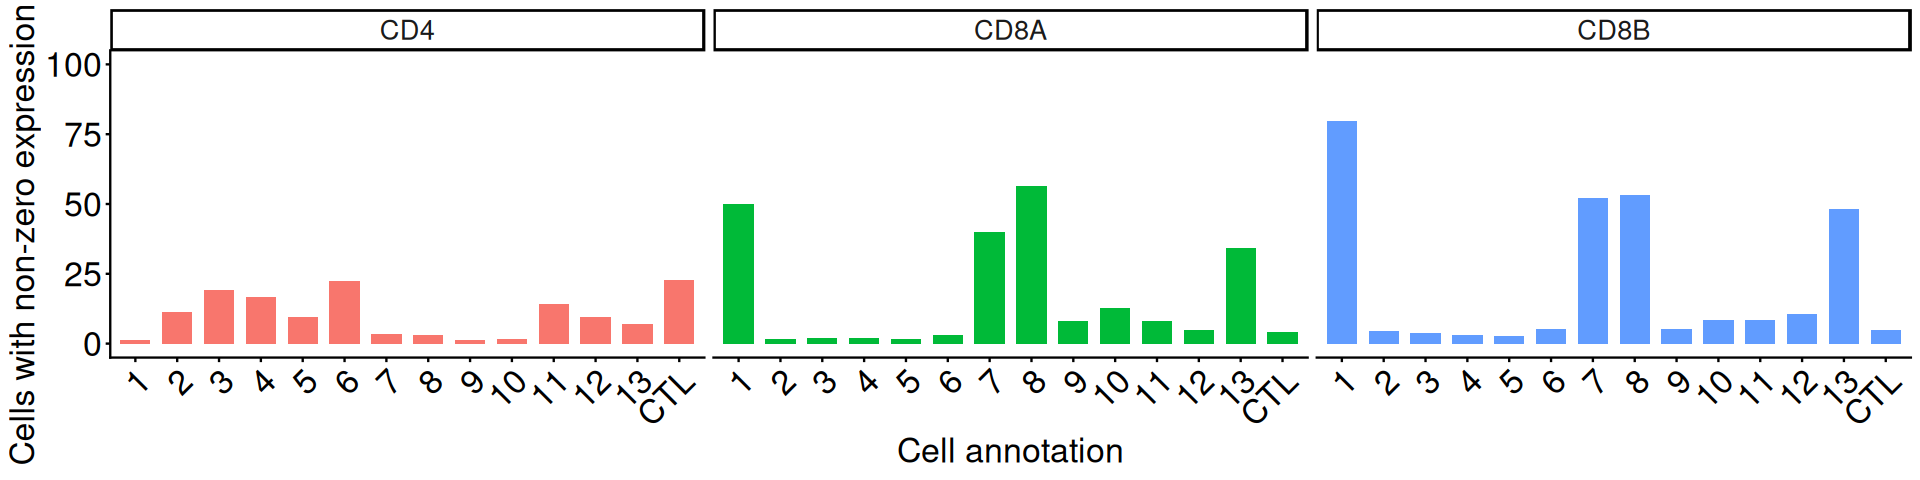

In [35]:
ggplot(df_summary,
       aes(x = seurat_clusters_and_ctl,
           y = percent_positive,
           fill = gene)) +
  geom_col(width = 0.7) +
  facet_wrap(~ gene, nrow = 1) +
  scale_y_continuous(limits = c(0, 100)) +
  labs(
    x = "Cell annotation",
    y = "Cells with non-zero expression (%)"
  ) +
  theme_classic() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "none"
  ) +
ggtheme()

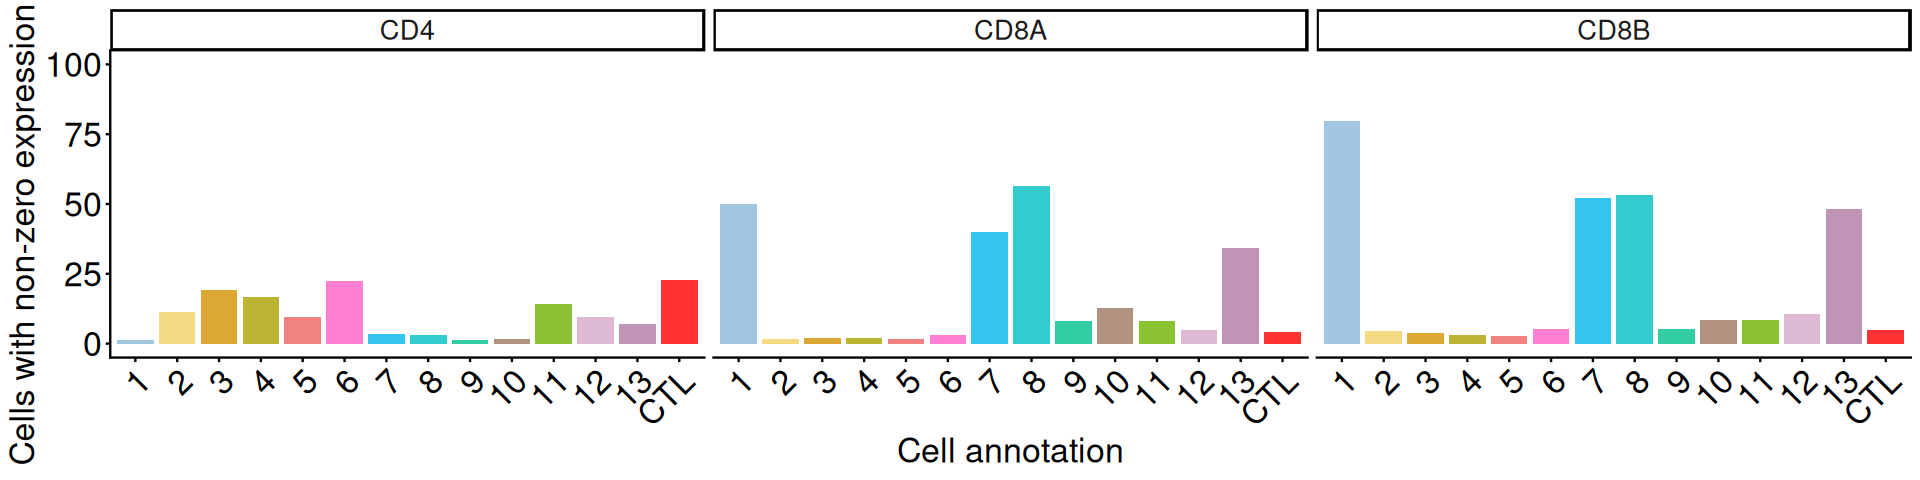

In [37]:
options(repr.plot.width = 16, repr.plot.height = 4)
ggplot(df_summary,
       aes(x = seurat_clusters_and_ctl,
           y = percent_positive,
           fill = seurat_clusters_and_ctl)) +
  geom_col(width = 0.85, alpha = 0.8) +
  facet_wrap(~ gene, nrow = 1) +
  scale_fill_manual(values = pallete_blood_5p) +
  scale_y_continuous(limits = c(0, 100)) +
  labs(
    x = "Cell annotation",
    y = "Cells with non-zero expression (%)"
  ) +
  theme_classic() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "none"
  ) +
ggtheme()

In [38]:
ggsave("figures/barplot_blood_cd4_cd8_3p.svg", width = 34, height = 9, units = "cm")
ggsave("figures/barplot_blood_cd4_cd8_3p.png", width = 34, height = 9, units = "cm")

In [40]:
rm(bl_3p)
rm(bl_5p)
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,12323818,658.2,25345077,1353.6,25345077,1353.6
Vcells,27474447,209.7,7571622039,57766.9,6464119351,49317.4
